## Swinburne University COS60008 Introduction to Data Science, Semester 1 2026, Project
# PhiUSIIL Phishing URL Dataset
### Author: Catherine Attard (Student ID 106185149)

## Part 1: Problem Formulation, Data Acquisition and Preparation

### Data Acquisition

The dataset used for this project is the PhiUSIIL Phishing URL Dataset (Prasad & Chandra, 2024a), hosted on the University of California Irvine (UCI) Machine Learning Repository (Prasad & Chandra, 2024b). The dataset contains data relating to 134,850 legitimate URLs and 100,945 phishing URLs. There are 54 dataset features, including attributes of the URLs themselves, the corresponding website HTML code and comparison against a list of popular legitimate websites.

The dataset is available at https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

The UCI Machine Learning Repository provides a custom Python library for downloading datasets. The library can be installed using ```pip``` as shown below.

In [1]:
# Install library to download data directly from UCI repo 
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Load Data

The below code attempts to load the data from a local directory, as this is faster than downloading it from UCI. If the data is not already available locally, then it is downloaded and saved locally so it will be available the next time the code is run.

In [2]:
from ucimlrepo import fetch_ucirepo # For downloading data from UCI repo
import pathlib 
import pandas as pd

# Directory for storing data
data_dir = pathlib.Path('PhiUSIIL Data')
if not data_dir.exists():
    data_dir.mkdir()

try:
    # Load data from local directory
    X = pd.read_csv(data_dir / 'X.csv')
    y = pd.read_csv(data_dir / 'y.csv')
    # a = c
except:
    # Import data using code provided on UCI repo webpage (Prasad & Chandra, 2024b)
    phiusiil_phishing_url_website = fetch_ucirepo(id=967) # fetch dataset
  
    # metadata 
    print(phiusiil_phishing_url_website.metadata) 
  
    # variable information 
    print(phiusiil_phishing_url_website.variables)

    # data (as pandas dataframes) 
    X = phiusiil_phishing_url_website.data.features 
    y = phiusiil_phishing_url_website.data.targets

    # Save data to local directory
    X.to_csv(data_dir / 'X.csv', index=False)
    y.to_csv(data_dir / 'y.csv', index=False)

In [3]:
# Preview dataframe headers
pd.set_option('display.max_columns', 60)
print('Features dataframe header:')
print(X.head())
print('\nTarget dataframe header:')
print(y.head())

Features dataframe header:
                                  URL  URLLength                      Domain  \
0    https://www.southbankmosaics.com         31    www.southbankmosaics.com   
1            https://www.uni-mainz.de         23            www.uni-mainz.de   
2      https://www.voicefmradio.co.uk         29      www.voicefmradio.co.uk   
3         https://www.sfnmjournal.com         26         www.sfnmjournal.com   
4  https://www.rewildingargentina.org         33  www.rewildingargentina.org   

   DomainLength  IsDomainIP  TLD  URLSimilarityIndex  CharContinuationRate  \
0            24           0  com               100.0              1.000000   
1            16           0   de               100.0              0.666667   
2            22           0   uk               100.0              0.866667   
3            19           0  com               100.0              1.000000   
4            26           0  org               100.0              1.000000   

   TLDLegitimateProb  U

### Data Preparation

The labels are added to the feature dataframe to assist with the data exploration phase.

In [4]:
X = pd.concat([X, y], axis=1)
print(X.head())

                                  URL  URLLength                      Domain  \
0    https://www.southbankmosaics.com         31    www.southbankmosaics.com   
1            https://www.uni-mainz.de         23            www.uni-mainz.de   
2      https://www.voicefmradio.co.uk         29      www.voicefmradio.co.uk   
3         https://www.sfnmjournal.com         26         www.sfnmjournal.com   
4  https://www.rewildingargentina.org         33  www.rewildingargentina.org   

   DomainLength  IsDomainIP  TLD  URLSimilarityIndex  CharContinuationRate  \
0            24           0  com               100.0              1.000000   
1            16           0   de               100.0              0.666667   
2            22           0   uk               100.0              0.866667   
3            19           0  com               100.0              1.000000   
4            26           0  org               100.0              1.000000   

   TLDLegitimateProb  URLCharProb  TLDLength  NoOf

# Part 2: Exploration

In [5]:
# Set up directory to save plots
plot_dir = pathlib.Path('Plots')
if not plot_dir.exists():
    plot_dir.mkdir()

### Question 1: How does top level domain (TLD) relate to the legitimacy of a website URL?

The top level domain (TLD) of a URL is the last part of the domain name. For example, in the URL ```https://topaka.cloud/ob52gtplj/18snwp```, the domain name is ```topaka.cloud``` and the TLD is ```cloud```.

A phishing URL that is attempting to imitate a legitimate website will often use a different TLD from that used in the legitimate website's URL (Prasad & Chandra 2024a). Exploring the relationship between TLD values and website legitimacy can help to identify phishing URLs based on the presence of particular TLDs. 

In [6]:
# Print total number of unique TLDs
tld_unique = X['TLD'].unique()
print(f'Identified {len(tld_unique)} unique TLDs.') 

Identified 695 unique TLDs.


TLDs are aggregated based on the counts of legitimate and phishing URLs with the given TLD.

In [7]:
tld_counts = X[['TLD', 'label']].value_counts().unstack() # Count TLD occurences in legitimate and phishing URLs
tld_counts.fillna(0, inplace=True) # Fill missing values with 0

tld_counts.rename(columns={0: 'Total Phishing', 1: 'Total Legitimate'}, inplace=True)

tld_counts['Total Count'] = tld_counts['Total Phishing'] + tld_counts['Total Legitimate']

# Calculate proportional values
tld_counts['Legitimate Proportion'] = tld_counts['Total Legitimate'] / tld_counts['Total Count']
tld_counts['Phishing Proportion'] = tld_counts['Total Phishing'] / tld_counts['Total Count']

print(tld_counts.head())

label  Total Legitimate  Total Phishing  Total Count  Legitimate Proportion  \
TLD                                                                           
com             68785.0         43769.0     112554.0               0.611129   
de               3310.0           686.0       3996.0               0.828328   
uk               6073.0           322.0       6395.0               0.949648   
org             16524.0          2269.0      18793.0               0.879264   
in                842.0           537.0       1379.0               0.610587   

label  Phishing Proportion  
TLD                         
com               0.388871  
de                0.171672  
uk                0.050352  
org               0.120736  
in                0.389413  


A binomial test (The SciPy community, n.d.-b) is used to determine which of the following categories each TLD falls in:
* Likely Legitimate: URLs with the given TLD are more likely to be legitimate URLs than phishing URLs
* Likely Phishing: URLs with the given TLD are more likely to be phishing URLs than legitimate URLs
* Indeterminate: URLs with the given TLD have around equal chance of being a phishing URL or legitimate URL

The binomial test returns a confidence interval for the likelihood that a URL with the given TLD belongs to a legitimate website. If the lower bound of the confidence interval is greater than $0.5$, then the TLD is classed as 'Likely Legitimate'. If the upper bound of the confidence interval is less than $0.5$, then the TLD is classed as 'Likely Phishing'. If $0.5$ falls within the confidence interval, then the URL is classed as 'Indeterminate'.

In [8]:
from scipy.stats import binomtest

# Helper function to calculate confidence interval for each row
def get_confidence_interval(x):
    y = x # Initialise return row
    confidence_level = 0.95

    # Calculate confidence interval
    confidence_interval = binomtest(k = int(x['Total Legitimate']), n=int(x['Total Count'])).proportion_ci(confidence_level=confidence_level)
    y['p_low'] = confidence_interval.low
    y['p_high'] = confidence_interval.high

    if confidence_interval.low < 0.5 and confidence_interval.high < 0.5:
        y['Likely Phishing'] = True # URLs with the given TLD are more than 50% likely to be legitimate websites
        y['Word Cloud Colour'] = 'red'
        y['Plot Order'] = confidence_interval.high # Value to determine plotting order
        y['Word Cloud Size'] = 1 - confidence_interval.high
    elif confidence_interval.low > 0.5 and confidence_interval.high > 0.5:
        y['Likely Legitimate'] = True # URLs with the given TLD are more than 50% likely to be phishing websites
        y['Word Cloud Colour'] = 'yellow'
        y['Plot Order'] = confidence_interval.low
        y['Word Cloud Size'] = confidence_interval.low

    return y

# Initialise columns assuming all TLDs are indeterminate
tld_counts['p_low'] = 0
tld_counts['p_high'] = 1
tld_counts['Likely Legitimate'] = False
tld_counts['Likely Phishing'] = False
tld_counts['Word Cloud Colour'] = 'orange'
tld_counts['Plot Order'] = 0.5
tld_counts['Word Cloud Size'] = 0.5

tld_counts = tld_counts.apply(get_confidence_interval, axis=1)

print(tld_counts.sample(10))

label      Total Legitimate  Total Phishing  Total Count  \
TLD                                                        
tokyo                   8.0             9.0         17.0   
161                     0.0             1.0          1.0   
pink                    0.0             1.0          1.0   
206                     0.0             4.0          4.0   
faith                   1.0             0.0          1.0   
71                      0.0             1.0          1.0   
211:8383                0.0             1.0          1.0   
com                 68785.0         43769.0     112554.0   
254:30332               0.0             1.0          1.0   
12                      0.0            16.0         16.0   

label      Legitimate Proportion  Phishing Proportion     p_low    p_high  \
TLD                                                                         
tokyo                   0.470588             0.529412  0.229833  0.721882   
161                     0.000000             1.0

The confidence intervals for each of the top 30 legitimate TLDs and phishing TLDs are shown on area plots using the matplotlib ```fill_between``` method (Hunter et al., 2026). The TLDs are displayed on the horizontal axis, ordered by their likelihood of belonging to a legitimate URL.

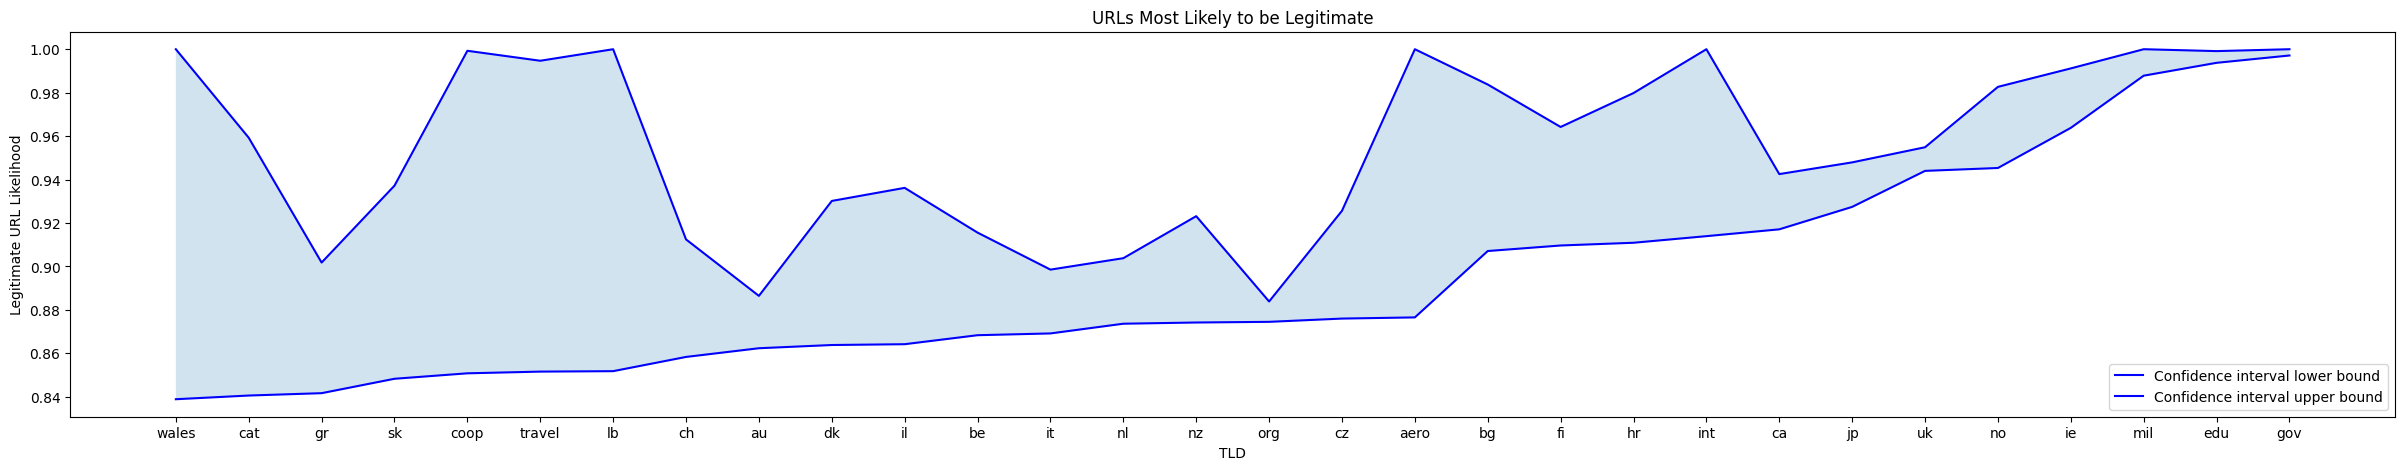

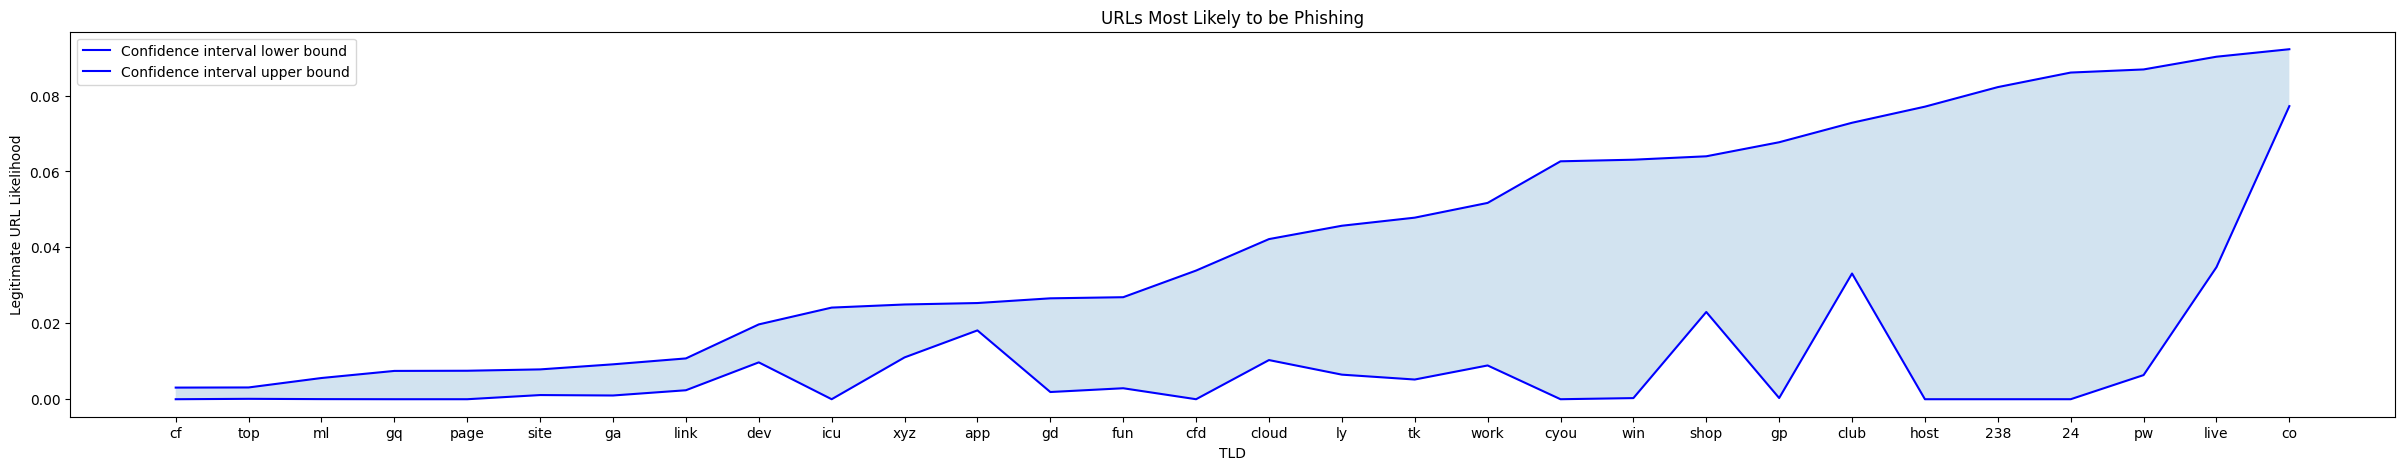

In [9]:
from matplotlib import pyplot as plt # For plots/visualisations

# Plotting function
def plot_tld(x, title, tick_interval=50):
    x = x.sort_values(['Plot Order', 'Legitimate Proportion']) # Sort by likelihood of legitimacy, using confidence interval bounds for URLs that are more likely legitimate or more likely phishing 

    ticks = list(range(0, len(x), tick_interval)) # TLD-axis tick locations

    # Plot line chart 
    ax = x.plot.line(y=['p_low', 'p_high'], 
                     title=title,
                     ylabel='Legitimate URL Likelihood',
                     color='blue',
                     figsize=(len(ticks),5))
    ax.fill_between(x.index, x['p_low'], x['p_high'], alpha=0.2)
    ax.legend(['Confidence interval lower bound', 'Confidence interval upper bound'])

    # Position TLD axis ticks
    tld_list = x.index.to_list()
    tick_labels = tld_list[0: : tick_interval]
    ax.set_xticks(ticks,labels=tick_labels)

    return ax

# Set up directory to save plots
tld_dir = plot_dir / 'TLDs'
if not tld_dir.exists():
    tld_dir.mkdir()

# Separate dataframe into phishing, legitimate and undetermined/unsure
legit_tld = tld_counts[tld_counts['Likely Legitimate']]
phish_tld = tld_counts[tld_counts['Likely Phishing']]

# Plot top 30 legitimate URLs
plot_tld(legit_tld.nlargest(n=30, columns='Plot Order'), title='URLs Most Likely to be Legitimate', tick_interval=1)
plt.savefig(tld_dir / 'TopLegitTLD.png')

# Plot top 30 phishing URLs
plot_tld(phish_tld.nsmallest(n=30, columns='Plot Order'), title='URLs Most Likely to be Phishing', tick_interval=1)
plt.savefig(tld_dir / 'TopPhishTLD.png')

All of the TLDs are visualised in a word cloud using the ```wordcloud``` library (Mueller, 2020). TLDs in the 'Likely Phishing' category appear in red, TLDs in the 'Likely Legitimate' category appear in yellow and TLDs in the 'Indeterminate' category appear in orange. The size of the red and yellow TLDs correspond to their respective likelihoods of belonging to a phishing URL or legitimate URL.

In [10]:
# Install wordcloud library
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


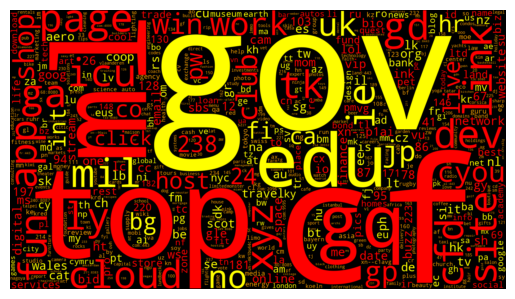

In [11]:
from wordcloud import WordCloud # For TLD word cloud visualisations

tld_counts['Word Cloud Size'] = tld_counts['Word Cloud Size']
wc_size_dict = tld_counts['Word Cloud Size'].to_dict() # Create dictionary of TLD sizes
wc_colour_dict = tld_counts['Word Cloud Colour'].to_dict() # Create dictionary of TLD colours

# Colour function to pass to word cloud generator
def assign_wc_colours(word, font_size=None, position=None, orientation=None, random_state=None, font_path=None):
    return wc_colour_dict[word]

# Generate word cloud
wc = WordCloud(width=1600, height=900, color_func=assign_wc_colours, relative_scaling=1, max_words=len(tld_counts))
wc.generate_from_frequencies(wc_size_dict)
plt.axis("off")
plt.imshow(wc, interpolation="bilinear")
plt.show()
wc.to_file(tld_dir / 'WordCloud.png')

### Question 2: How does URL length relate to the legitimacy of a website URL?

Phishing URLs often have a higher character length than legitimate URLs (Prasad & Chandra, 2024a). Exploring the relationship between URL length and website legitimacy can help to identify when a URL is likely to belong to a phishing website based on excessive length.

Confidence intervals are calculated using dataset quantiles (The SciPy community, n.d.-c) to determine the typical URL length ranges for legitimate and phishing URLs. The lower bounds are similar for both phishing URLs and legitimate URLs, but the upper bounds for phishing URLs are much higher than those for legitimate URLs. This suggests that very long URLs are very likely to be phishing URLs. 

In [12]:
from scipy.stats import quantile

# Calculate Z2 and Z3 confidence intervals
cf_phish = quantile(X[X['label']==0]['URLLength'], [0.025, 0.975, 0.0015, 0.9985])
cf_legit = quantile(X[X['label']==1]['URLLength'], [0.025, 0.975, 0.0015, 0.9985])

# Print results
print('URL Length 95% confidence interval')
print(f'Phishing websites: {cf_phish[0]} - {cf_phish[1]}')
print(f'Legitimate websites: {cf_legit[0]} - {cf_legit[1]}')
print('\n 99.7% confidence interval')
print(f'Phishing websites: {cf_phish[2]} - {cf_phish[3]}')
print(f'Legitimate websites: {cf_legit[2]} - {cf_legit[3]}')

URL Length 95% confidence interval
Phishing websites: 19.0 - 135.0
Legitimate websites: 18.0 - 37.0

 99.7% confidence interval
Phishing websites: 15.0 - 475.0
Legitimate websites: 17.0 - 44.0


A two sample t-test is used to test the hypothesis that phishing URLs are longer than legitimate URLs on average. The resulting p-value is zero, which indicates that phishing URLs are almost certainly longer on average.

In [13]:
from scipy.stats import ttest_ind

p = ttest_ind(X[X['label']==0]['URLLength'], 
              X[X['label']==1]['URLLength'], 
              alternative='greater'
              ).pvalue

print(f'Hypothesis test p-value: {p}')

Hypothesis test p-value: 0.0


URL lengths are expected to fit a gamma distribution, as URLs have a minimum length of 1 character and URL frequency is expected to decay with increasing length.

In [14]:
from scipy.stats import gamma

# Fit gamma distributions
gamma_phish = gamma.fit(X[X['label']==0]['URLLength'])
gamma_legit = gamma.fit(X[X['label']==1]['URLLength'])

The URL length distributions for legitimate and phishing websites are plotted in histograms overlaid with the fitted gamma distributions. The legitimate URL lengths fit the corresponding gamma distribution very well, but the phishing URLs have a more irregular distribution that does not fit a gamma distribution well. The difference in the length distributions for legitimate and phishing URLs is shown in the first plot, where it is apparent that phishing URLs can have much longer typical lengths than legitimate URLs.

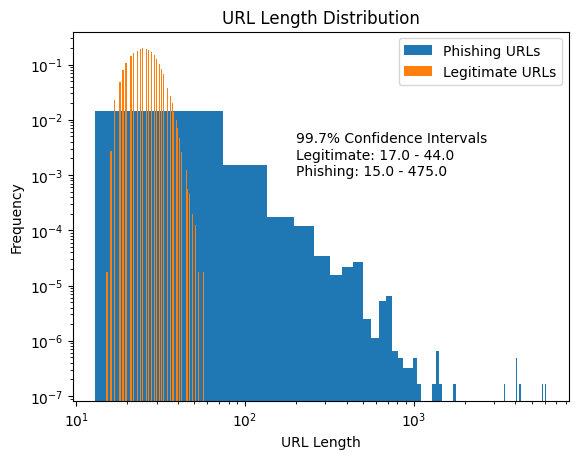

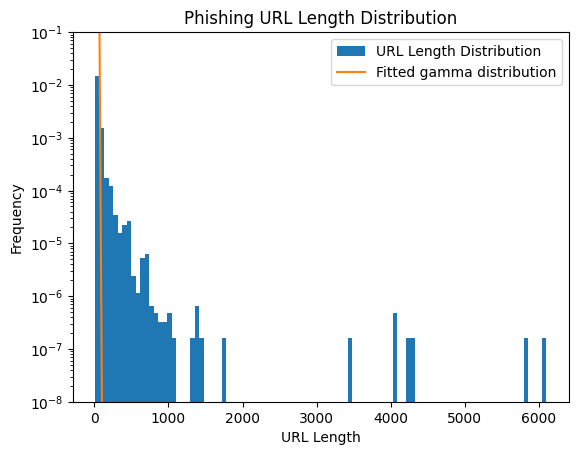

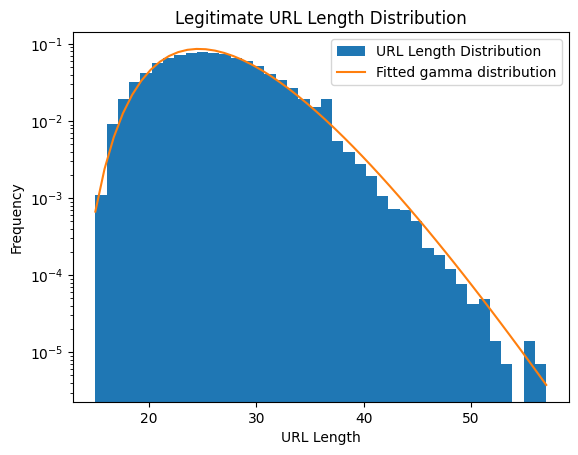

In [15]:
import numpy as np

# Set up directory to save plots
url_length_dir = plot_dir / 'URL Length'
if not url_length_dir.exists():
    url_length_dir.mkdir()

fig = plt.figure()
ax = X[X['label']==0]['URLLength'].plot.hist(bins=100, density=True, loglog=True) # Distribution for phishing URLs
X[X['label']==1]['URLLength'].plot.hist(ax=ax, bins=100, density=True, loglog=True, title='URL Length Distribution', xlabel='URL Length') # Distribution for legitimate URLs
ax.legend(['Phishing URLs', 'Legitimate URLs'])
plt.annotate(f'99.7% Confidence Intervals\nLegitimate: {cf_legit[2]} - {cf_legit[3]}\nPhishing: {cf_phish[2]} - {cf_phish[3]}', 
             (2e2, 1e-3))
plt.savefig(url_length_dir / 'Both.png')

fig = plt.figure()
ax = X[X['label']==0]['URLLength'].plot.hist(bins=100, density=True, log=True, title='Phishing URL Length Distribution', xlabel='URL Length')
x = np.linspace(min(X[X['label']==0]['URLLength']), max(X[X['label']==0]['URLLength']),50)
ax.plot(x, gamma.pdf(x, a=gamma_phish[0], loc=gamma_phish[1], scale=gamma_phish[2]))
ax.set(ylim = (1e-8, 1e-1))
ax.legend(['URL Length Distribution', 'Fitted gamma distribution'])
plt.savefig(url_length_dir / 'PhishFitted.png')

fig = plt.figure()
ax = X[X['label']==1]['URLLength'].plot.hist(bins=40, density=True, log=True, title='Legitimate URL Length Distribution', xlabel='URL Length')
x = np.linspace(min(X[X['label']==1]['URLLength']), max(X[X['label']==1]['URLLength']),50)
ax.plot(x, gamma.pdf(x, a=gamma_legit[0], loc=gamma_legit[1], scale=gamma_legit[2]))
ax.legend(['URL Length Distribution', 'Fitted gamma distribution'])
plt.savefig(url_length_dir / 'LegitFitted.png')

### Question 3: How does the presence of pop-ups relate to the legitimacy of a website?

Phishing websites may attempt to obtain sensitive information by distracting users with pop-ups, indicated by a ```window.open``` tag in the website's HTML code (Prasad & Chandra, 2024a). Exploring the relationship between pop-up frequency and website legitimacy can help to determine whether a website with several pop-ups is likely to be a phishing website. 

Similar to the URL lengths explored in question 2, confidence intervals are calculated using dataset quantiles, to determine the typical number of pop-ups on legitimate websites and phishing websites. Although phishing websites can use pop-ups as a strategy to obtain user information, legitimate websites actually have a higher upper bound on the number of pop-ups than phishing websites. This suggests that the presence of pop-ups alone does not indicate that a website is a phishing site.

In [16]:
cf_phish = quantile(X[X['label']==0]['NoOfPopup'], [0.025, 0.975, 0.0015, 0.9985])
cf_legit = quantile(X[X['label']==1]['NoOfPopup'], [0.025, 0.975, 0.0015, 0.9985])

# Print results
print('Number of pop-ups 95% confidence interval')
print(f'Phishing websites: {cf_phish[0]} - {cf_phish[1]}')
print(f'Legitimate websites: {cf_legit[0]} - {cf_legit[1]}')
print('\n 99.7% confidence interval')
print(f'Phishing websites: {cf_phish[2]} - {cf_phish[3]}')
print(f'Legitimate websites: {cf_legit[2]} - {cf_legit[3]}')

Number of pop-ups 95% confidence interval
Phishing websites: 0.0 - 0.0
Legitimate websites: 0.0 - 2.0

 99.7% confidence interval
Phishing websites: 0.0 - 2.0
Legitimate websites: 0.0 - 32.0


A two sample t-test is used to test the hypothesis that phishing websites have fewer pop-ups than legitimate websites on average. The resulting p-value is very close to zero, which indicates that phishing websites almost certainly have fewer pop-ups on average.

In [17]:
from scipy.stats import ttest_ind

p = ttest_ind(X[X['label']==0]['NoOfPopup'], 
              X[X['label']==1]['NoOfPopup'], 
              alternative='less'
              ).pvalue

print(f'Hypothesis test p-value: {p}')

Hypothesis test p-value: 1.3005690332089057e-117


The pop-up distributions for legitimate and phishing websites are plotted in histograms. The difference in the distribution of pop-ups for legitimate and phishing websites is shown in the first plot, where it is apparent that legitimate websites can have a higher typical number of pop-ups than phishing websites.

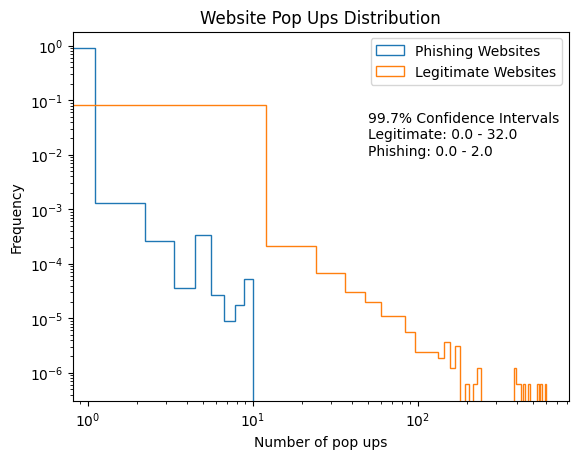

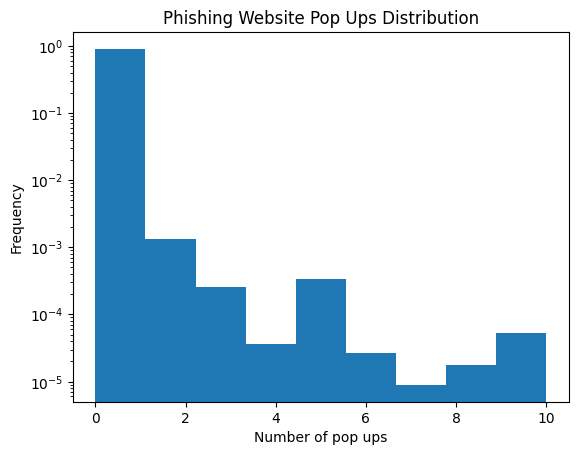

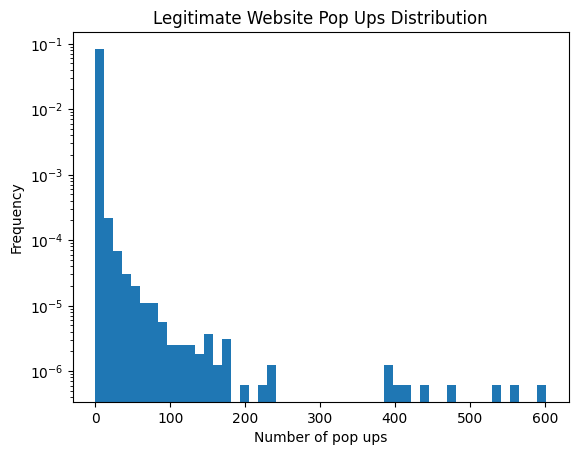

In [18]:
# Set up directory to save plots
popup_dir = plot_dir / 'Pop Ups'
if not popup_dir.exists():
    popup_dir.mkdir()

# Plot both distributions
fig = plt.figure()
ax = X[X['label']==0]['NoOfPopup'].plot.hist(bins=9, density=True, loglog=True, histtype='step') # Distribution for phishing URLs
X[X['label']==1]['NoOfPopup'].plot.hist(ax=ax, bins=50, density=True, loglog=True, histtype='step', title='Website Pop Ups Distribution', xlabel='Number of pop ups') # Distribution for legitimate URLs
ax.legend(['Phishing Websites', 'Legitimate Websites'])
plt.annotate(f'99.7% Confidence Intervals\nLegitimate: {cf_legit[2]} - {cf_legit[3]}\nPhishing: {cf_phish[2]} - {cf_phish[3]}', 
             (50, 1e-2))
plt.savefig(popup_dir / 'Both.png')

# Plot phishing website distribution
fig = plt.figure()
ax = X[X['label']==0]['NoOfPopup'].plot.hist(bins=9, density=True, log=True, title='Phishing Website Pop Ups Distribution', xlabel='Number of pop ups')
plt.savefig(popup_dir / 'Phish.png')

# Plot legitimate website distribution
fig = plt.figure()
ax = X[X['label']==1]['NoOfPopup'].plot.hist(bins=50, density=True, log=True, title='Legitimate Website Pop Ups Distribution', xlabel='Number of pop ups')
plt.savefig(popup_dir / 'Legit.png')

## Part 3: Feature Engineering and Supervised Learning

### Feature Engineering

The models used for supervised learning require numerical features, so dummy variables are created to convert the TLD from a string valued categorical attribute to a set of binary valued numerical attributes.

In [19]:
tld_dummies = pd.get_dummies(X['TLD'], prefix='TLD') # Get dummy variables
X = pd.concat([X, tld_dummies], axis=1) # Add dummy variable columns to main dataframe
X = X.replace(to_replace={True: 1.0, False: 0.0}) # Convert boolean values to integers

print(X.head()) # Preview updated dataframe

                                  URL  URLLength                      Domain  \
0    https://www.southbankmosaics.com         31    www.southbankmosaics.com   
1            https://www.uni-mainz.de         23            www.uni-mainz.de   
2      https://www.voicefmradio.co.uk         29      www.voicefmradio.co.uk   
3         https://www.sfnmjournal.com         26         www.sfnmjournal.com   
4  https://www.rewildingargentina.org         33  www.rewildingargentina.org   

   DomainLength  IsDomainIP  TLD  URLSimilarityIndex  CharContinuationRate  \
0            24           0  com               100.0              1.000000   
1            16           0   de               100.0              0.666667   
2            22           0   uk               100.0              0.866667   
3            19           0  com               100.0              1.000000   
4            26           0  org               100.0              1.000000   

   TLDLegitimateProb  URLCharProb  TLDLength  NoOf

In the dataset, phishing URLs are labelled as '0' and legitimate URLs are labelled as '1'. However, the aim of performing binary classification on this dataset is to identify and potentially block phishing URLs, so phishing URLs should be treated as the 'positive' class (labelled as '1') when calculating performance metrics like precision and accuracy. To enable correct performance metric calculations, the data labels are swapped, so that a label of '0' now corresponds to a legitimate URL and a label of '1' corresponds to a phishing URL.

In [20]:
y = y.replace({0: 1, 1: 0}) # Swap labels so phishing URLs are labelled as 1

### Training / Test Split

The scikit-learn ```train_test_split``` method (scikit-learn developers, 2026g) is used to separate the dataset into training and testing sets. 80% of the data is used in the training set and 20% is used in the test set.

In [21]:
from sklearn.model_selection import train_test_split

seed_val = 42 # random state value for repeatability

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_val)

# Preview split dataframes
print('Training features')
print(X_train.head())
print('\nTesting features')
print(X_test.head())
print('\nTraining labels')
print(y_train.head())
print('\nTesting labels')
print(y_test.head())

Training features
                                                  URL  URLLength  \
125096             https://3.daviplataactivo.repl.co/         33   
52769                            http://www.ole32.com         19   
202217                       https://www.cowtales.com         23   
35039   https://miseenjourdigitalisation2023.web.app/         44   
57443                      https://www.karenlepage.me         25   

                                      Domain  DomainLength  IsDomainIP  TLD  \
125096             3.daviplataactivo.repl.co            25           0   co   
52769                          www.ole32.com            13           0  com   
202217                      www.cowtales.com            16           0  com   
35039   miseenjourdigitalisation2023.web.app            36           0  app   
57443                     www.karenlepage.me            18           0   me   

        URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  \
125096           29.649226 

### Data Preparation

Supervised learning models tend to work with numeric data only, so non-numeric attributes are removed from the dataset before training. The dataset contains several numeric attributes derived from these non-numeric attributes, which are sufficient for model prediction. The label column is also removed from the features dataframe now that it is no longer required for data exploration tasks.

In [22]:
text_cols = ['URL', 'Domain', 'TLD', 'Title', 'label']
X_train_numeric = X_train.drop(text_cols, axis=1)
X_test_numeric = X_test.drop(text_cols, axis=1)

### Supervised Learning Option 1: Random Forest Classifier

A random forest estimator uses an ensemble of decision tree base estimators to improve generalisability and robustness in comparison to a single decision tree estimator (scikit-learn developers, 2026b). A random forest classifier has been selected as the first supervised learning option, as decision trees require minimal data preparation (scikit-learn developers, 2026a), making the classifier straightforward to implement in comparison to other supervised learning options that may require data standardisation or normalisation prior to training.

#### Tune hyperparameters

Hyperparameters are tuned using the sklearn RandomizedSearchCV class (scikit-learn developers, 2026f). The class requires a random distribution for each hyperparameter. 

An exponential distribution has been selected for the ```min_impurity_decrease``` and ```ccp_alpha``` hyperparameter values as the default value for these hyperparameters is also the minimum value. The exponential distribution returns samples that are close to the default, but always greater.

A gamma distribution has been selected for the ```n_estimators``` hyperparameter values as these have a minimum allowed value and a default value above the minimum. A gamma distribution with a peak at the default value returns samples close to the default and greater than the minimum value. The probability density function (PDF) of a gamma distribution is given by: 

$$f\left(x\right) = \frac{y^{\alpha - 1}e^{-\frac{y}{\theta}}}{\Gamma\left(\alpha\right)\theta^\alpha}\text{,}$$

where $\alpha$ and $\theta$ correspond to the SciPy distribution parameters ```a``` and ```scale```, and $y = x - c$, where $c$ corresponds to the location parameter ```loc``` (The SciPy community, n.d.-d).

A gamma distribution's mode, $x_{\text{mode}}$, occurs at the stationary point of the PDF, which is given by $y_{\text{mode}} = \theta\left(\alpha - 1\right)$, where $y_{\text{mode}} = x_{\text{mode}} - c$. $\alpha$ is set to $2$ for simplicity and the scale value is then given by $\theta = y_{\text{mode}}$. The ```loc``` value is set to the minimum hyperparameter value.

A beta distribution has been selected for the ```min_samples_split```, ```min_samples_leaf``` and ```max_samples``` hyperparameter values, as these are required to fall between $0$ and $1$. The PDF of a beta distribution is given by:

$$f\left(x\right) = \frac{\Gamma\left(a + b\right)x^{a-1}\left(1 - x\right)^{b-1}}{\Gamma\left(a\right)\Gamma\left(b\right)}\text{,}$$

where $a, b \gt 0$ (The SciPy community, n.d.-a).

If $a \lt 1$, then the beta distribution has a vertical asymptote at $x=0$ and if $b \lt 1$, then the distribution has a vertical asymptote at $x=1$.

```min_samples_split``` and ```min_samples_leaf``` are expected to have values close to zero, which is achieved by setting $a$ close to zero. The value of $b$ is set slightly larger than 1 to ensure the PDF value is zero at $x=1$ and the distribution tail is relatively flat.

```max_samples``` is expected to have a value close to 1, so for this hyperparameter, the distribution parameters are set to $a = 2$ and $b = 1$, reducing the distribution to a sawtooth shape with a mode at 1.

The selected distributions are plotted to demonstrate that the distribution shapes are as expected.

Text(0.5, 1.0, 'max_samples Distribution')

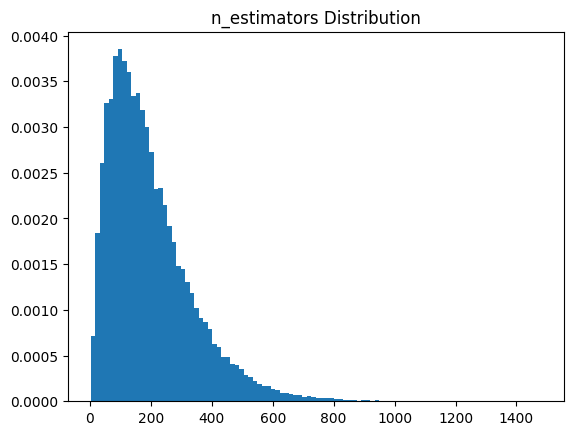

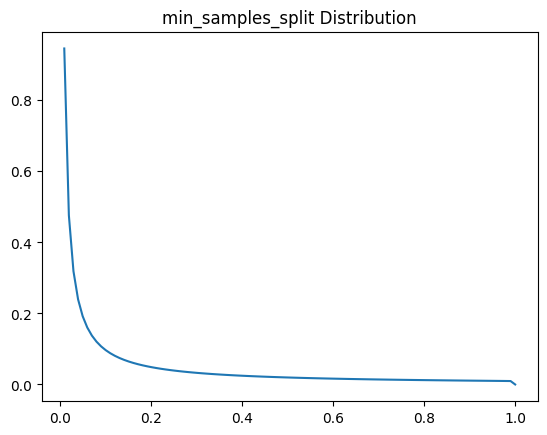

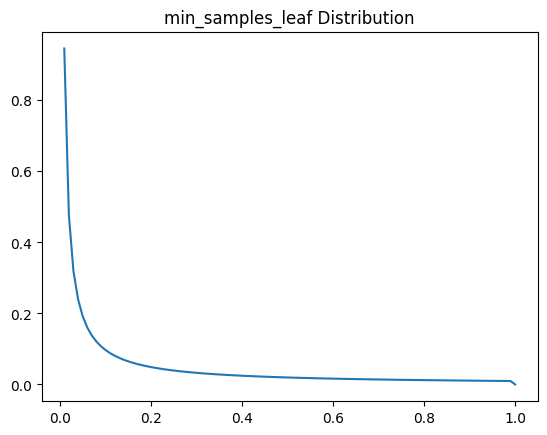

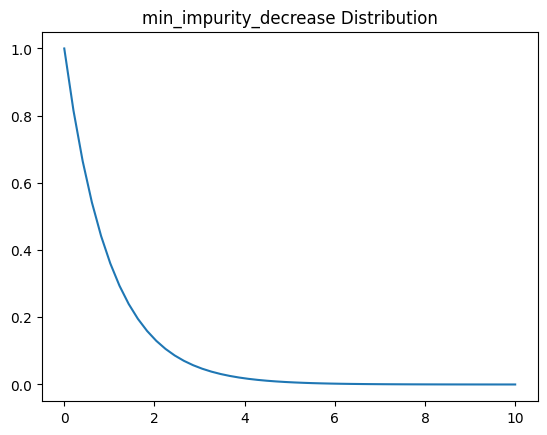

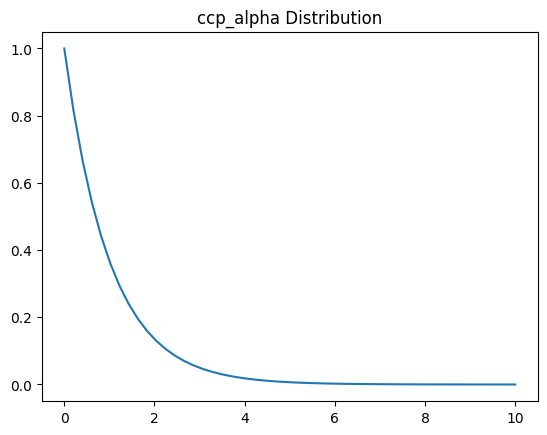

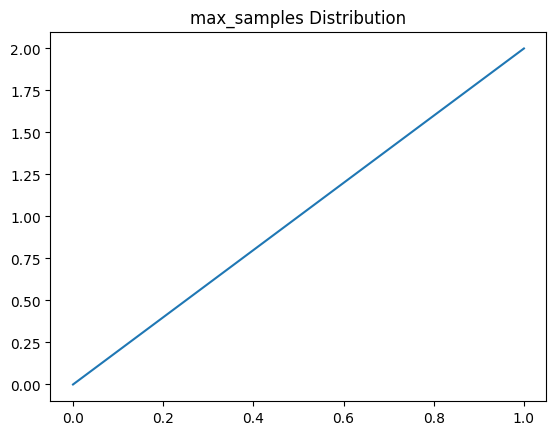

In [23]:
from scipy.stats import expon, beta

# Function to create exponential distribution for randomize search CV
def get_expon_dist(x_min):
    return expon(loc=x_min)

# Function to create gamma distribution for randomize search CV
def get_gamma_dist(x_mode, x_min):
    return gamma(a=2, loc=x_min, scale=x_mode - x_min)

# Function to sample integer values from a gamma distribution
def get_gamma_ints(x_mode, x_min):
    return get_gamma_dist(x_mode, x_min).rvs(size=100000, random_state=seed_val).astype(np.int64)

# Hyperparameter probability distributions
dist_dict = {'n_estimators': get_gamma_ints(100, 2),
             'min_samples_split': beta(a=0.01, b=1.01),
             'min_samples_leaf': beta(a=0.01, b=1.01),
             'min_impurity_decrease': get_expon_dist(0),
             'ccp_alpha': get_expon_dist(0),
             'max_samples': beta(a=2, b=1),
             }

# Plot distributions to check they are correct
plt.figure()
plt.hist(dist_dict['n_estimators'], bins=100, density=True)
plt.title('n_estimators Distribution')

plt.figure()
x = np.linspace(0, 1, 100)
plt.plot(x, dist_dict['min_samples_split'].pdf(x))
plt.title('min_samples_split Distribution')

plt.figure()
x = np.linspace(0, 1, 100)
plt.plot(x, dist_dict['min_samples_leaf'].pdf(x))
plt.title('min_samples_leaf Distribution')

plt.figure()
x = np.linspace(0, 10, 50)
plt.plot(x, dist_dict['min_impurity_decrease'].pdf(x))
plt.title('min_impurity_decrease Distribution')

plt.figure()
x = np.linspace(0, 10, 50)
plt.plot(x, dist_dict['ccp_alpha'].pdf(x))
plt.title('ccp_alpha Distribution')

plt.figure()
x = np.linspace(0, 1, 20)
plt.plot(x, dist_dict['max_samples'].pdf(x))
plt.title('max_samples Distribution')


The result of the hyperparameter tuning is a trained random forest classifier with prediction accuracy of 97.2% on the test data.

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Classifier object for tuning
rf_classifier = RandomForestClassifier(n_jobs=-1, random_state=seed_val)

# Tune hyperparameters
tuner = RandomizedSearchCV(estimator=rf_classifier, param_distributions=dist_dict, random_state=seed_val)
search = tuner.fit(X_train_numeric, y_train.to_numpy().ravel())

best_classifier = search.best_estimator_ # Random forest classifier with optimised parameters

# Print results
print('Best test score:')
print(best_classifier.score(X_test_numeric, y_test))

Best test score:
0.9720307894569435


Each decision tree in the random forest outputs a class probability value for each input data point, and the random forest takes the mean of the individual tree class probabilities to make a final prediction (scikit-learn developers, 2026b). If the mean probability is above a particular threshold (decision threshold), then the URL is labelled as a phishing URL. Otherwise, the URL is labelled as legitimate. The model's performance can be improved by tuning the decision threshold using the scikit-learn TunedThresholdClassifierCV class (scikit-learn developers, 2026h).

In [25]:
from sklearn.model_selection import TunedThresholdClassifierCV

# Train final model using best parameters from tuning stage
rf_classifier_tuned = TunedThresholdClassifierCV(best_classifier,
                                                 scoring='f1', # Optimise F1 score to balance between precision and recall
                                                 cv=0.2, # Use 20% of data for validation
                                                 random_state=seed_val)
rf_classifier_tuned.fit(X_train_numeric, y_train.to_numpy().ravel())

# Print results
print(f'Best decision threshold: {rf_classifier_tuned.best_threshold_}')
print(f'Best F1 score: {rf_classifier_tuned.best_score_}')

Best decision threshold: 0.43559088052884787
Best F1 score: 0.9903423512660187


The final model's performance on the test dataset is measured using accuracy, precision, recall and F1 score metrics, and visualised with a confusion matrix. Tuning the decision threshold has increased the test data accuracy by just over 2% to 99.38%. The precision, recall and F1 metrics are all above 99% also.

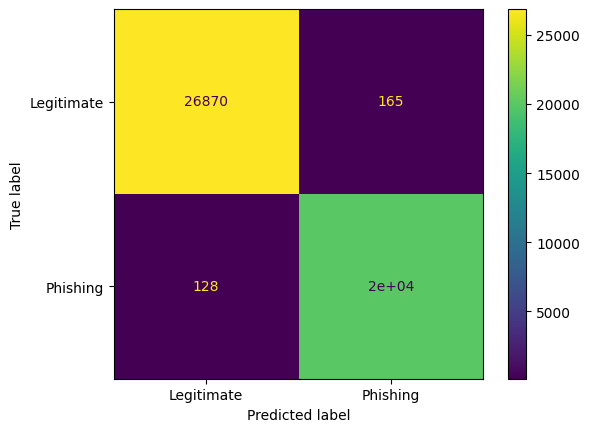

Accuracy: 99.38 %
Precision: 99.18 %
Recall: 99.36 %
F1 score: 99.27 %


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score

# Get test predictions
y_pred = rf_classifier_tuned.predict(X_test_numeric)

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing'])
disp.plot()
plt.show()

# Calculate performance metrics
acc = 100 * accuracy_score(y_test, y_pred)
prec = 100 * precision_score(y_test, y_pred)
recall = 100 * recall_score(y_test, y_pred)
f1 = 100 * f1_score(y_test, y_pred)

# Print metrics
print(f'Accuracy: {acc:.2f} %')
print(f'Precision: {prec:.2f} %')
print(f'Recall: {recall:.2f} %')
print(f'F1 score: {f1:.2f} %')

### Supervised Learning Option 2: Multi-Layer Perceptron (MLP) Classifier

A multi-layer perceptron (MLP) is a neural network that uses weighted linear summations and non-linear activations to transform the input features for a given data point into a corresponding class prediction (scikit-learn developers, 2026c). MLP has been selected as the second supervised learning option as it can capture non-linear relationships between features and classes.

#### Normalisation

Because multi-layer perceptron models are sensitive to feature scaling, the data needs to be normalised or standardised before training (scikit-learn developers, 2026c). Most of the features in the dataset already have binary values (0 or 1), so the remaining features are normalised using the scikit-learn quantile transformer class (scikit-learn developers, 2026e). 

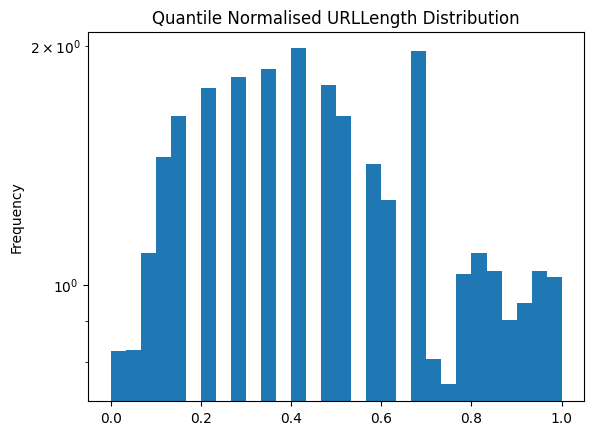

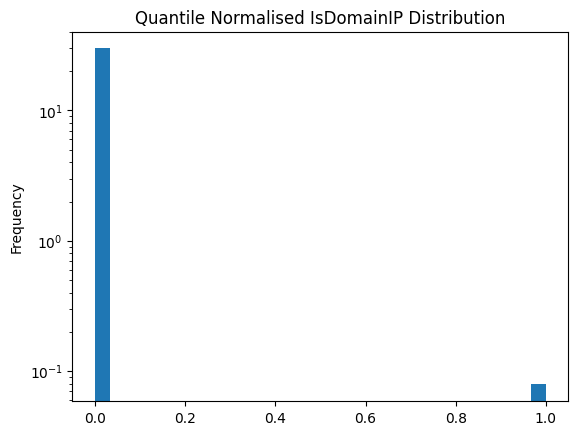

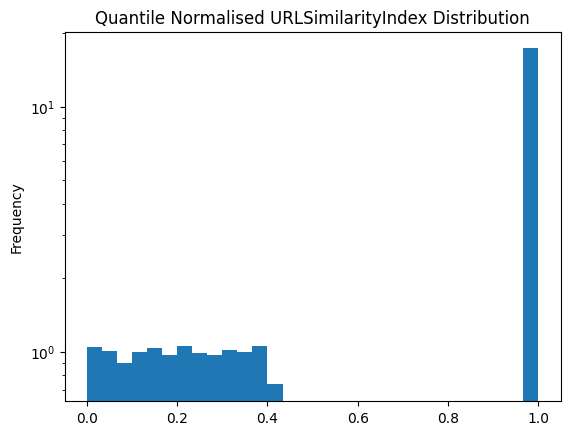

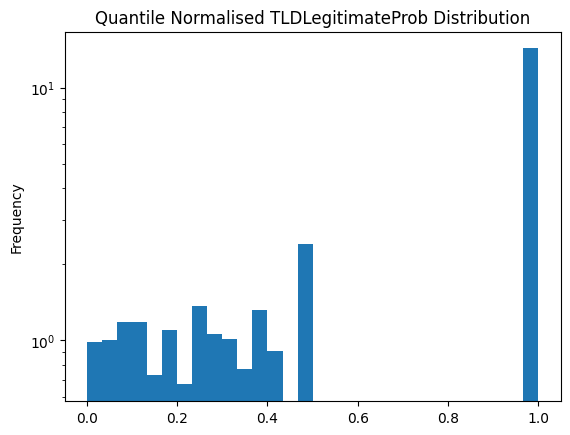

In [27]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution='uniform', random_state=seed_val) # Quantile transformer with uniform distribution output
qt.fit(X_train_numeric) # Fit quantile transformer to training data

# Apply quantile transformer to training and test data
qt.set_output(transform='pandas')
X_train_norm = qt.transform(X_train_numeric)
X_test_norm = qt.transform(X_test_numeric)

# Plot sample of standardised data
sample_cols = ['URLLength', # Integer >0
               'IsDomainIP', # Binary 0/1
               'URLSimilarityIndex', # Continuous 0-100
               'TLDLegitimateProb' # Continuous 0-1
               ]

for col in sample_cols:
    plt.figure()
    X_train_norm[col].plot.hist(bins=30, density=True, log=True, title=f'Quantile Normalised {col} Distribution')

### Dimension Reduction

Dimension reduction is performed using the scikit learn incremental principle component analysis (PCA) class (scikit-learn developers, 2026d). This improves training and prediction time by reducing the number of inputs to the MLP.

Components with an explained variance below 1% are discarded. An initial PCA is performed to view an explained variance plot.

Text(0, 0.5, 'Explained Variance Ratio')

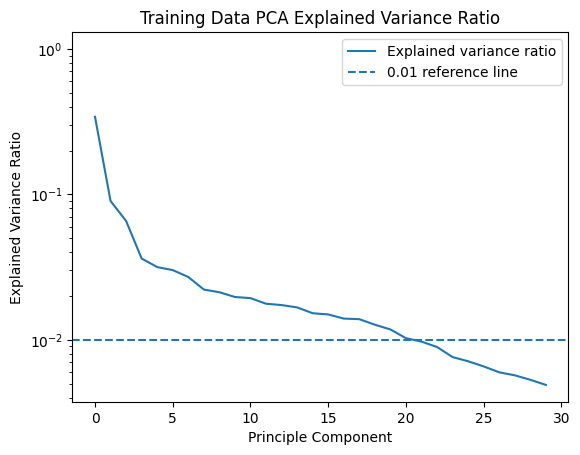

In [28]:
from sklearn.decomposition import IncrementalPCA

t_var = 0.01 # Explained variance threshold

X_PCA = IncrementalPCA(n_components=30).fit(X_train_norm) # Perform PCA on training data

# Plot explained variance
r_var = X_PCA.explained_variance_ratio_

plt.figure()
plt.plot(list(range(len(r_var))), r_var)
plt.title('Training Data PCA Explained Variance Ratio')
plt.axhline(y=t_var, linestyle='--')
plt.legend(['Explained variance ratio', f'{t_var} reference line'])
plt.semilogy(True)
plt.xlabel('Principle Component')
plt.ylabel('Explained Variance Ratio')

A second PCA is performed using only the components above the 1% explained variance threshold.

In [29]:
n_components = len(r_var) # Initial value for number of components

for k, v in enumerate(r_var):
    if v < t_var:
        n_components = k
        break

X_PCA = IncrementalPCA(n_components=n_components).fit(X_train_norm) # Perform PCA on training data

# Reduce data
X_train_reduced = X_PCA.transform(X_train_norm)
X_test_reduced = X_PCA.transform(X_test_norm)

#### Tune hyperparameters

Similar to the random forest classifier, the MLP classifier hyperparameters are tuned using the sklearn RandomizedSearchCV class.

A gamma distribution has been selected for the ```alpha``` and initial learning rate hyperparameter values as these are assumed to all be positive. As with the random forest classifier, the distribution parameters are set based on the hyperparameter default and minimum values. The minimum values are set slightly above zero to avoid sampling zero values for these parameters.

A beta distribution has been selected for the ```beta_1``` and ```beta_2``` hyperparameter values, as these are required to fall between $0$ and $1$. A beta distribution's mode occurs at the PDF's stationary point, which is given by $x_{\text{mode}} = \frac{a - 1}{a + b - 2}$. Setting $a = 2$ for simplicity, the value of $b$ is then given by $b = \frac{1}{x_{\text{mode}}}$. The mode is set to the default hyperparameter value.

The selected distributions are plotted to demonstrate that the distribution shapes are as expected.

Text(0.5, 1.0, 'beta_2 Distribution')

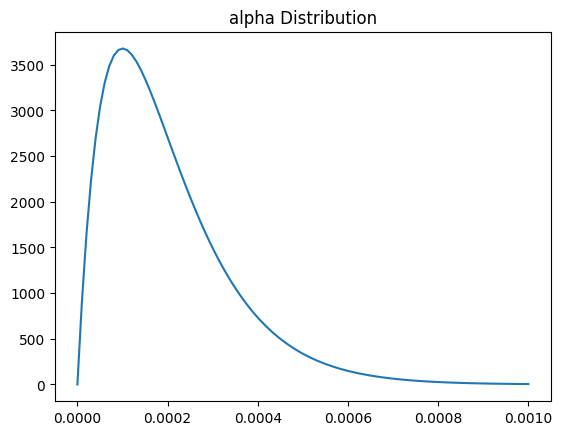

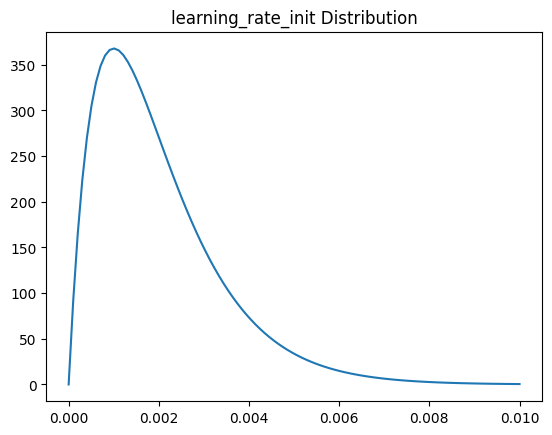

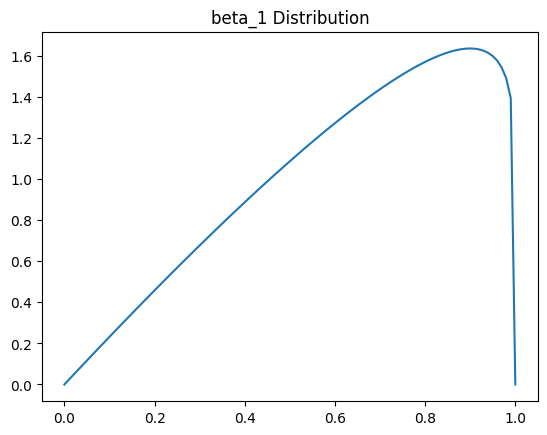

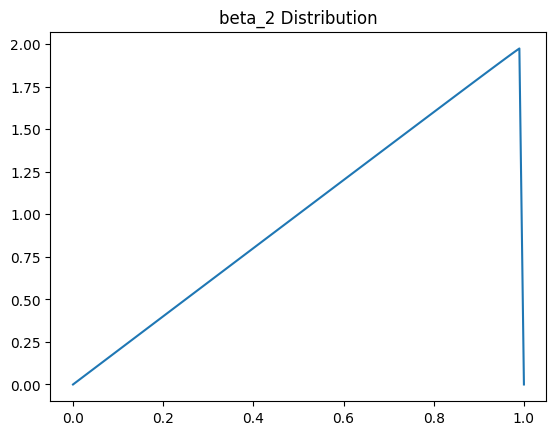

In [30]:
from scipy.stats import beta, gamma

# Function to create gamma distribution for randomize search CV
def get_gamma_dist(x_mode, x_min):
    return gamma(a=2, loc=x_min, scale=x_mode - x_min)

#Function to create beta distribution for randomize search CV
def get_beta_dist(x_mode):
    return beta(a=2, b=1/x_mode)

# Hyperparameter probability distributions
dist_dict = {'alpha' : get_gamma_dist(0.0001, 1e-16),
             'learning_rate_init': get_gamma_dist(0.001, 1e-15),
             'beta_1': get_beta_dist(0.9),
             'beta_2': get_beta_dist(0.999)
             }

# Plot distributions to check they are correct
plt.figure()
a = np.linspace(start=0, stop=0.001, num=100)
plt.plot(a, dist_dict['alpha'].pdf(a))
plt.title('alpha Distribution')

plt.figure()
lr = np.linspace(0, 0.01, 100)
plt.plot(lr, dist_dict['learning_rate_init'].pdf(lr))
plt.title('learning_rate_init Distribution')

plt.figure()
b1 = np.linspace(0, 1, 100)
plt.plot(b1, dist_dict['beta_1'].pdf(b1))
plt.title('beta_1 Distribution')

plt.figure()
b2 = np.linspace(0, 1, 100)
plt.plot(b2, dist_dict['beta_2'].pdf(b2))
plt.title('beta_2 Distribution')

The result of the hyperparameter tuning is a trained random MLP classifier with prediction accuracy of 99.9788% on the test data.

In [31]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV

# Classifier object for tuning
classifier = MLPClassifier(random_state=seed_val, # Set random state for reproducibility
                                early_stopping=True, # Enable early stopping to automatically set aside validation dataset
                                validation_fraction=0.2, # Set aside 20% of dataset for validation
                                max_iter=50 # Maximum training iterations
                                )

# Tune hyperparameters
tuner = RandomizedSearchCV(estimator=classifier, param_distributions=dist_dict, random_state=seed_val)
search = tuner.fit(X_train_reduced, y_train.to_numpy().ravel())

best_classifier = search.best_estimator_ # MLP classifier with optimised parameters

# Print results
print('Best test score:')
print(best_classifier.score(X_test_reduced, y_test))

Best test score:
0.9997879513984606


The best model found during hyperparameter tuning is trained on the entire training dataset using a higher number of maximum iterations. The training stops early after 14 iterations as the training loss is no longer improving.

Text(0, 0.5, 'Training Loss')

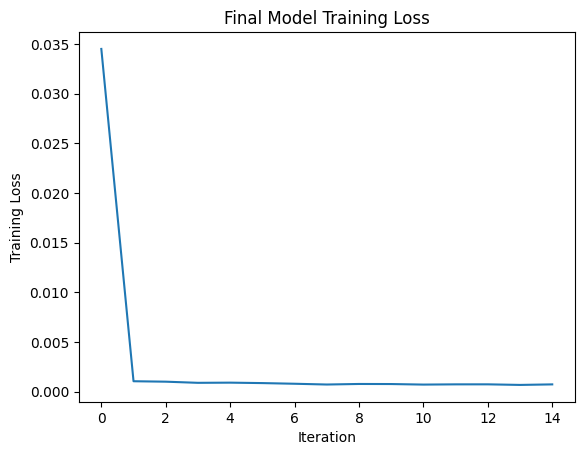

In [32]:
# Train final model using best parameters from tuning stage
final_classifier = MLPClassifier(random_state=seed_val, # Set random state for reproducibility
                                 alpha=search.best_params_['alpha'],
                                 learning_rate_init=search.best_params_['learning_rate_init'],
                                 beta_1=search.best_params_['beta_1'],
                                 beta_2=search.best_params_['beta_2'],
                                 max_iter=200 # Maximum training iterations
                                )

final_classifier.fit(X_train_reduced, y_train.to_numpy().ravel())

plt.plot(final_classifier.loss_curve_)
plt.title('Final Model Training Loss')
plt.xlabel('Iteration')
plt.ylabel('Training Loss')

The MLP classifier outputs a class probability value for each input data point. Similar to the random forest, a decision threshold is used to determine the predicted class and this decision threshold is tuned to improve the model performance.

In [33]:
from sklearn.model_selection import TunedThresholdClassifierCV

final_classifier_tuned = TunedThresholdClassifierCV(final_classifier, 
                                                    scoring='f1', # Optimise F1 score to balance between precision and recall
                                                    cv=0.2, # Use 20% of data for validation
                                                    random_state=seed_val
                                                    )
final_classifier_tuned.fit(X_train_reduced, y_train.to_numpy().ravel()) # Tune threshold

# Print results
print(f'Best decision threshold: {final_classifier_tuned.best_threshold_}')
print(f'Best F1 score: {final_classifier_tuned.best_score_}')

Best decision threshold: 0.08080808080808081
Best F1 score: 0.9998144368157358


The final model's performance on the test dataset is measured using accuracy, precision, recall and F1 score metrics, and visualised with a confusion matrix. Tuning the decision threshold has marginally increased the test data accuracy, which was already above 99.9% before tuning. The precision, recall and F1 metrics are all above 99.9% also.

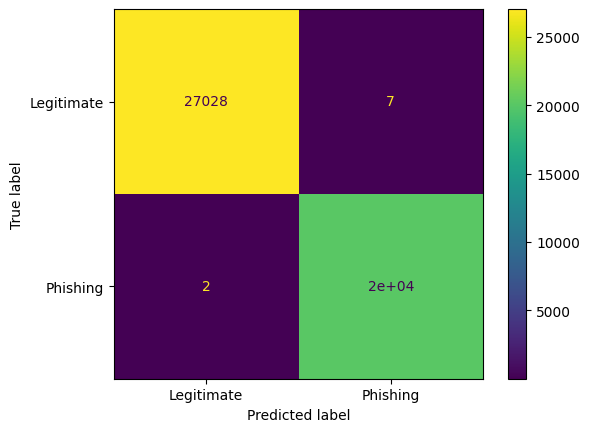

Accuracy: 99.9809 %
Precision: 99.9652 %
Recall: 99.9901 %
F1 score: 99.9776 %


In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, precision_score, recall_score

# Get test predictions
y_pred = final_classifier_tuned.predict(X_test_reduced)

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing'])
disp.plot()
plt.show()

# Calculate performance metrics
acc = 100 * accuracy_score(y_test, y_pred)
prec = 100 * precision_score(y_test, y_pred)
recall = 100 * recall_score(y_test, y_pred)
f1 = 100 * f1_score(y_test, y_pred)

# Print metrics
print(f'Accuracy: {acc:.4f} %')
print(f'Precision: {prec:.4f} %')
print(f'Recall: {recall:.4f} %')
print(f'F1 score: {f1:.4f} %')

### Supervised Learning Model Recommendation

The MLP classifier model is recommended for phishing URL detection. Although the random forest classifier also performed well on the dataset, the MLP performed better across all four of the evaluated performance metrics. The MLP classifier also has particularly good recall at over 99.99%, so it is capable of successfully detecting almost all phishing websites.

## References

Hunter, J., Dale, D., Firing, E., Droettboom, M., & The Matplotlib development team. (2026). matplotlib.axes.Axes.fill between. https://matplotlib.org/stable/api/as_gen/matplotlib.axes.Axes.fill_between.html

Mueller, A. (2020). WordCloud for Python documentation. https://amueller.github.io/word cloud/index.html

Prasad, A., & Chandra, S. (2024a). A diverse security profile empowered phishing URL detection framework based on similarity index and incremental learning. Computers & Security, 136. https://doi.org/https://doi.org/10.1016/j.cose.2023.103545

Prasad, A., & Chandra, S. (2024b). PhiUSIIL Phishing URL (Website). UC Irvine Machine Learning Repository. https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

scikit-learn developers. (2026a). 1.10. Decision Trees. https://scikit-learn.org/stable/modules/tree.html

scikit-learn developers. (2026b). 1.11. Ensembles: Gradient boosting, random forests, bagging, voting, stacking. https://scikit-learn.org/stable/modules/ensemble.html

scikit-learn developers. (2026c). 1.17. Neural network models (supervised). https://scikit-learn.org/stable/modules/neural_networks_supervised.html

scikit-learn developers. (2026d). IncrementalPCA. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.IncrementalPCA.html

scikit-learn developers. (2026e). QuantileTransformer. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html

scikit-learn developers. (2026f). RandomizedSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html

scikit-learn developers. (2026g). train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

scikit-learn developers. (2026h). TunedThresholdClassifierCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html

The SciPy community. (n.d.-a). scipy.stats.beta. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html

The SciPy community. (n.d.-b). binomtest. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html

The SciPy community. (n.d.-c). quantile. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.quantile.html

The SciPy community. (n.d.-d). scipy.stats.gamma. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html